<a href="https://colab.research.google.com/github/nilaynishant/acrs/blob/main/05_Data_Loading_and_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Notebook 1 – Data Loading and Feature Engineering
### GeoAI for Future Earth | ACRS Training Workshop 2026

**Learning objectives:**
- Load Sentinel-2 imagery with **rioxarray** and explore its metadata
- Visualise multispectral composites
- Compute spectral indices (NDVI, NDWI, SAVI, EVI) and stack them as new bands
- Extract pixel values at training locations for machine learning

**Data:** Sentinel-2 L2A scene over Agartala, India (4 bands @ 10 m)
**Classes:** Vegetation · Builtup · Water · Agriculture · Fallow


## 0 · Setup

In [ ]:
%%capture
!pip install rioxarray geopandas xarray matplotlib numpy pandas seaborn


In [ ]:
import os, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import geopandas as gpd
import xarray as xr
import rioxarray as rxr
warnings.filterwarnings('ignore')

print("All libraries imported successfully.")


All libraries imported successfully.


In [ ]:
# Clone the tutorial repository (contains raster and vector data)
REPO_URL = 'https://github.com/nilaynishant/AIMLTutorial.git'
REPO_DIR = '/content/AIMLTutorial'

if not os.path.exists(REPO_DIR):
    result = subprocess.run(['git', 'clone', '--depth=1', REPO_URL, REPO_DIR],
                            capture_output=True, text=True, check=True)
    print("Repository cloned successfully.")
else:
    print("Repository already present.")

RASTER_PATH = f'{REPO_DIR}/Data/Sentinel2_Agartala.tif'
POINTS_PATH  = f'{REPO_DIR}/Data/Training.gpkg'
print(f"Raster : {RASTER_PATH}")
print(f"Points : {POINTS_PATH}")


Repository cloned successfully.
Raster : /content/AIMLTutorial/Data/Sentinel2_Agartala.tif
Points : /content/AIMLTutorial/Data/Training.gpkg


## 1 · Loading Raster Data with rioxarray

[rioxarray](https://corteva.github.io/rioxarray/) extends xarray with spatial I/O and CRS-aware operations, making raster workflows intuitive and pandas-like.

In [ ]:
# Open raster – returns an xarray.DataArray with dims (band, y, x)
img = rxr.open_rasterio(RASTER_PATH)
print("=== Raster Metadata ===")
print(f"  Shape       : {img.shape}  (bands, rows, cols)")
print(f"  CRS         : {img.rio.crs}")
print(f"  Bounds      : {img.rio.bounds()}")
print(f"  Resolution  : {img.rio.resolution()} degrees")
print(f"  NoData      : {img.rio.nodata}")
img


=== Raster Metadata ===
  Shape       : (4, 1938, 2202)  (bands, rows, cols)
  CRS         : EPSG:4326
  Bounds      : (91.20774742722325, 23.757474824523747, 91.40555645278637, 23.931568326586113)
  Resolution  : (8.983152841195215e-05, -8.983152841195215e-05) degrees
  NoData      : None


<xarray.DataArray (band: 4, y: 1938, x: 2202)> Size: 137MB
[17069904 values with dtype=float64]
Coordinates:
  * band         (band) int64 32B 1 2 3 4
  * y            (y) float64 16kB 23.93 23.93 23.93 23.93 ... 23.76 23.76 23.76
  * x            (x) float64 18kB 91.21 91.21 91.21 91.21 ... 91.41 91.41 91.41
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('B8A', 'B4', 'B3', 'B2')

In [ ]:
# Assign meaningful band names (stored in TIF metadata)
# Band order: B8A (NIR), B4 (Red), B3 (Green), B2 (Blue)
img = img.assign_coords(band=['B8A', 'B4', 'B3', 'B2'])

print("Band statistics (raw DN):")
for b in img.band.values:
    da = img.sel(band=b)
    print(f"  {b:5s}  min={float(da.min()):6.0f}  max={float(da.max()):6.0f}  mean={float(da.mean()):6.0f}")


Band statistics (raw DN):
  B8A    min=   395  max=  4542  mean=  2408
  B4     min=   295  max=  4364  mean=   735
  B3     min=   417  max=  3992  mean=   800
  B2     min=   300  max=  3758  mean=   615


## 2 · Visualising the Raster

Different band combinations emphasise different land-cover types:
- **True Colour (RGB):** B4–B3–B2 → natural appearance
- **False Colour (NRG):** B8A–B4–B3 → healthy vegetation appears red

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, bands, title in zip(
        axes,
        [['B4', 'B3', 'B2'], ['B8A', 'B4', 'B3']],
        ['True Colour  (RGB)', 'False Colour  (NRG – vegetation = red)']):
    subset = img.sel(band=bands).astype(float)
    # Percentile stretch for display
    p2, p98 = float(subset.quantile(0.02)), float(subset.quantile(0.98))
    stretched = ((subset - p2) / (p98 - p2)).clip(0, 1)
    stretched.plot.imshow(ax=ax, add_colorbar=False)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_axis_off()

plt.suptitle('Sentinel-2 · Agartala, India', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


## 3 · Computing Spectral Indices

Spectral indices highlight land-surface properties by combining bands mathematically.

| Index | Formula | Target |
|-------|---------|--------|
| NDVI  | (NIR − Red) / (NIR + Red) | Vegetation density |
| NDWI  | (Green − NIR) / (Green + NIR) | Water bodies |
| SAVI  | 1.5 × (NIR − Red) / (NIR + Red + 0.5) | Vegetation with soil correction |
| EVI   | 2.5 × (NIR − Red) / (NIR + 6·Red − 7.5·Blue + 1) | Enhanced vegetation |

> **Note:** We first convert DN to surface reflectance by dividing by 10 000.

In [ ]:
# Scale raw DN → surface reflectance (Sentinel-2 standard scaling factor)
img_ref = img.astype(float) / 10000.0

nir   = img_ref.sel(band='B8A')   # Near-Infrared
red   = img_ref.sel(band='B4')    # Red
green = img_ref.sel(band='B3')    # Green
blue  = img_ref.sel(band='B2')    # Blue

print("Reflectance statistics (should be roughly 0 – 0.5):")
for name, band in [('NIR  (B8A)', nir), ('Red  (B4)', red),
                   ('Green(B3)', green), ('Blue (B2)', blue)]:
    print(f"  {name}  min={float(band.min()):.4f}  max={float(band.max()):.4f}  mean={float(band.mean()):.4f}")


Reflectance statistics (should be roughly 0 – 0.5):
  NIR  (B8A)  min=0.0395  max=0.4542  mean=0.2408
  Red  (B4)  min=0.0295  max=0.4364  mean=0.0735
  Green(B3)  min=0.0417  max=0.3992  mean=0.0800
  Blue (B2)  min=0.0300  max=0.3758  mean=0.0615


In [ ]:
# ── NDVI ──────────────────────────────────────────────────────
ndvi = (nir - red) / (nir + red)
ndvi = ndvi.where((nir + red) != 0)          # avoid 0/0

# ── NDWI (Gao 1996) ───────────────────────────────────────────
ndwi = (green - nir) / (green + nir)
ndwi = ndwi.where((green + nir) != 0)

# ── SAVI (L = 0.5 standard soil factor) ───────────────────────
savi = 1.5 * (nir - red) / (nir + red + 0.5)

# ── EVI ───────────────────────────────────────────────────────
evi = 2.5 * (nir - red) / (nir + 6.0 * red - 7.5 * blue + 1.0)
evi = evi.clip(-2, 2)                        # clip sensor-noise outliers

print("Index statistics:")
for name, idx in [('NDVI', ndvi), ('NDWI', ndwi), ('SAVI', savi), ('EVI', evi)]:
    print(f"  {name}  min={float(idx.min()):.3f}  max={float(idx.max()):.3f}  mean={float(idx.mean()):.3f}")


Index statistics:
  NDVI  min=-0.341  max=0.810  mean=0.530
  NDWI  min=-0.730  max=0.351  mean=-0.495
  SAVI  min=-0.188  max=0.596  mean=0.307
  EVI  min=-0.232  max=1.179  mean=0.342


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
cbar_kw   = {'orientation': 'horizontal', 'fraction': 0.046, 'pad': 0.06}

plots = [
    (ndvi, 'NDVI',  'RdYlGn', -1, 1),
    (ndwi, 'NDWI',  'Blues_r', -1, 1),
    (savi, 'SAVI',  'YlGn',   -1, 1),
    (evi,  'EVI',   'Greens', -1, 1),
]
for ax, (idx, title, cmap, vmin, vmax) in zip(axes.flat, plots):
    idx.plot.imshow(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
                   cbar_kwargs=cbar_kw, add_colorbar=True)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_axis_off()

plt.suptitle('Spectral Indices – Agartala, India', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 4 · Stacking Bands + Indices

We concatenate the 4 original reflectance bands with 4 derived indices to create an **8-band feature stack**.

In [ ]:
def _band(da, name):
    """Wrap a (y, x) DataArray into a (band, y, x) DataArray with one named band."""
    return da.expand_dims({'band': [name]})

stacked = xr.concat([
    img_ref,                          # B8A, B4, B3, B2
    _band(ndvi, 'NDVI'),
    _band(ndwi, 'NDWI'),
    _band(savi, 'SAVI'),
    _band(evi,  'EVI'),
], dim='band')

FEATURE_NAMES = stacked.band.values.tolist()
print(f"Stacked dataset  shape : {stacked.shape}")
print(f"Features ({len(FEATURE_NAMES)})        : {FEATURE_NAMES}")
stacked


In [ ]:
# Save stacked raster for use in other analysis
STACKED_PATH = '/content/stacked_features.tif'

# Remove or update the 'long_name' attribute to avoid band count mismatch error
if 'long_name' in stacked.attrs:
    del stacked.attrs['long_name']

stacked.rio.to_raster(STACKED_PATH)
print(f"Saved to {STACKED_PATH}")

Saved to /content/stacked_features.tif


## 5 · Feature Extraction at Training Locations

We sample pixel values from the stacked raster at each labelled training point to build a tabular dataset for supervised classification.

In [ ]:
CLASS_MAP = {1: 'Vegetation', 2: 'Builtup', 3: 'Water', 4: 'Agriculture', 5: 'Fallow'}

# Load and inspect training points
gdf = gpd.read_file(POINTS_PATH)
gdf['class_name'] = gdf['id'].map(CLASS_MAP)

print(f"Training points: {len(gdf)}")
print(gdf.groupby(['id', 'class_name']).size().rename('count').reset_index().to_string(index=False))


Training points: 51
 id  class_name  count
  1  Vegetation     10
  2     Builtup     10
  3       Water     10
  4 Agriculture     12
  5      Fallow      9


In [ ]:
# Reproject points to match raster CRS
gdf = gdf.to_crs(stacked.rio.crs)

# Vectorised nearest-neighbour sampling using xarray
xs = xr.DataArray(gdf.geometry.x.values, dims=['pts'])
ys = xr.DataArray(gdf.geometry.y.values, dims=['pts'])
sampled = stacked.sel(x=xs, y=ys, method='nearest')   # shape: (8 bands, 51 pts)

df_features = pd.DataFrame(sampled.values.T, columns=FEATURE_NAMES)
df_features.insert(0, 'label',      gdf['id'].values)
df_features.insert(1, 'class_name', gdf['class_name'].values)

print(f"Feature matrix shape: {df_features.shape}")
df_features


Feature matrix shape: (51, 10)


,label,class_name,B8A,B4,B3,B2,NDVI,NDWI,SAVI,EVI
0,1,Vegetation,0.2353,0.0430,0.0569,0.0446,0.690981,-0.610541,0.370615,0.414869
1,1,Vegetation,0.2664,0.0500,0.0601,0.0446,0.683944,-0.631853,0.397599,0.439159
2,1,Vegetation,0.2628,0.0451,0.0577,0.0433,0.707048,-0.639938,0.404196,0.450296
3,1,Vegetation,0.2335,0.0481,0.0613,0.0476,0.658381,-0.584125,0.355809,0.397820
4,1,Vegetation,0.2535,0.0679,0.0795,0.0607,0.577474,-0.522523,0.338934,0.384855
5,1,Vegetation,0.2839,0.0449,0.0575,0.0472,0.726886,-0.663152,0.432553,0.498207
6,1,Vegetation,0.2997,0.0526,0.0713,0.0492,0.701391,-0.615633,0.434882,0.495667
7,1,Vegetation,0.3023,0.0462,0.0688,0.0518,0.734864,-0.629210,0.452740,0.537573
8,1,Vegetation,0.3077,0.0588,0.0755,0.0537,0.679127,-0.605950,0.430871,0.494733
9,1,Vegetation,0.2839,0.0522,0.0603,0.0455,0.689378,-0.649622,0.415680,0.461241


## 6 · Exploratory Data Analysis

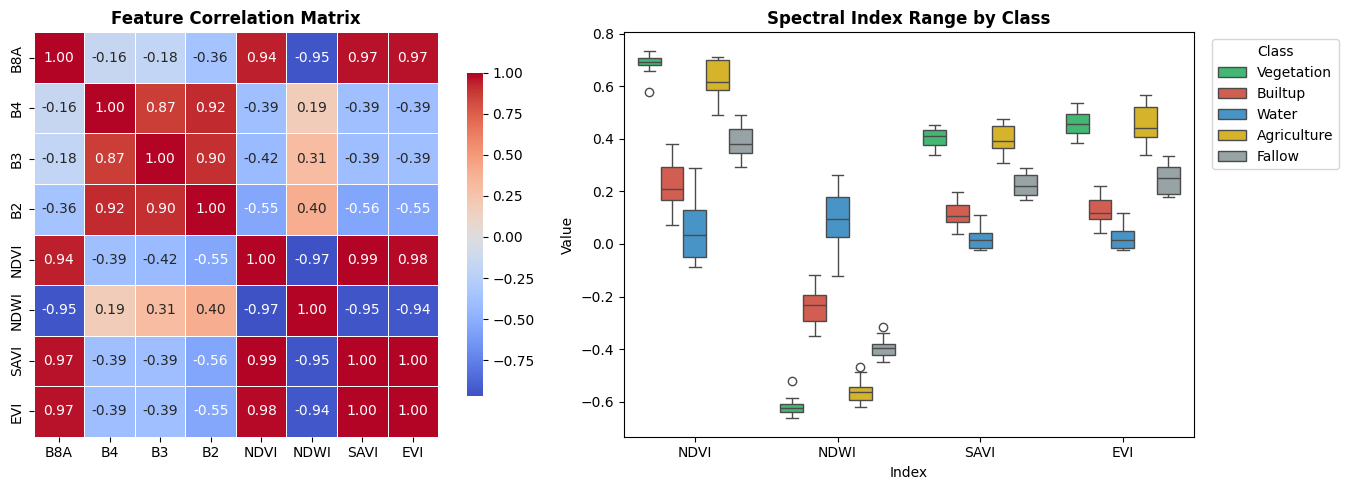

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Feature correlation heatmap
corr = df_features[FEATURE_NAMES].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, ax=axes[0], cbar_kws={'shrink': 0.8},
            linewidths=0.5)
axes[0].set_title('Feature Correlation Matrix', fontsize=12, fontweight='bold')

# Boxplot – indices by class
df_melt = df_features.melt(id_vars='class_name',
                            value_vars=['NDVI', 'NDWI', 'SAVI', 'EVI'],
                            var_name='Index', value_name='Value')
sns.boxplot(data=df_melt, x='Index', y='Value', hue='class_name',
            palette=LULC_COLORS, ax=axes[1])
axes[1].set_title('Spectral Index Range by Class', fontsize=12, fontweight='bold')
axes[1].legend(title='Class', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


# Exercises

 ## Compute GNDVI (NIR−Green)/(NIR+Green) and visualise

## Create a binary vegetation mask from NDVI > 0.3

## Summary

| Step | Output |
|------|--------|
| Load Sentinel-2 with rioxarray | 4-band DataArray (B8A, B4, B3, B2) |
| Scale to reflectance | Values in 0 – 0.5 range |
| Compute indices | NDVI, NDWI, SAVI, EVI |
| Stack all layers | 8-band DataArray |
| Sample at 51 training points | Feature matrix (51 × 10) |

**Next → Notebook 2:** Train SVM, Random Forest, and XGBoost with hyperparameter tuning.
